# 6. Explicabilité et équité

Explication globale (SHAP, permutation), explication d'une alerte (cascade et codes motifs), puis comparaison des alertes selon le genre et l'âge.

In [1]:
import sys
from pathlib import Path

RACINE = Path.cwd().resolve().parent
if str(RACINE) not in sys.path:
    sys.path.insert(0, str(RACINE))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", message="IProgress not found")
pd.options.display.float_format = "{:,.4f}".format
pd.options.display.max_columns = 30
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

BLEU = "#2a78d6"
ORANGE = "#eb6834"
VERT = "#1baf7a"
JAUNE = "#eda100"
ROSE = "#e87ba4"

In [2]:
from src import application, equite, explicabilite, modeles_supervises

modele = modeles_supervises.charger("xgboost")
echantillon = pd.read_parquet(RACINE / "app" / "ressources" / "echantillon_explication.parquet")
parametres = application.lire_parametres()
seuil = parametres["seuils"]["xgboost"]
echantillon.shape, seuil

((6210, 17), 0.027218025359384283)

## Importance globale

,importance_shap
amt,3.7670
heure,1.2864
category,1.2631
ratio_moy_30j,0.7858
delai_precedent,0.5328
z_montant_30j,0.3903
nb_tx_24h,0.2983
jour,0.1527
distance_km,0.1442
nb_tx_1h,0.0973


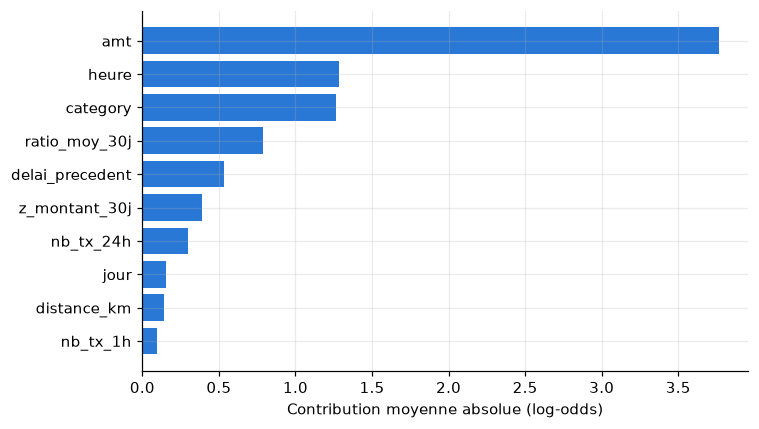

In [3]:
population = echantillon.sample(3000, random_state=0)
resultat = explicabilite.calculer_shap(modele, population)
importance = explicabilite.importance_shap(resultat.groupees())["importance"].sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(importance.index, importance.values, color=BLEU)
ax.set_xlabel("Contribution moyenne absolue (log-odds)")
fig.tight_layout()
importance.sort_values(ascending=False).to_frame("importance_shap")

In [4]:
permutation = pd.read_csv(RACINE / "resultats" / "importance_permutation.csv", index_col=0)
permutation.sort_values("perte_pr_auc", ascending=False)

,perte_pr_auc,ecart_type,pr_auc_reference
variable,,,
amt,0.9054,0.0005,0.9171
category,0.7255,0.0073,0.9171
heure,0.2170,0.0019,0.9171
ratio_moy_30j,0.1347,0.0018,0.9171
delai_precedent,0.0595,0.0008,0.9171
z_montant_30j,0.0424,0.0021,0.9171
nb_tx_24h,0.0170,0.0007,0.9171
nb_tx_1h,0.0054,0.0006,0.9171
jour,0.0014,0.0001,0.9171


## Explication d'une alerte

In [5]:
alerte = echantillon["probabilite"] >= seuil
fraude = echantillon["is_fraud"] == 1
detectees = echantillon[alerte & fraude].sort_values("probabilite", ascending=False)
ligne = detectees.iloc[[0]].reset_index(drop=True)
tableau = explicabilite.cascade(modele, ligne, 0)
tableau

,variable,code,libelle,contribution
0,amt,MONTANT,"Montant : 953,66",8.2506
1,heure,HEURE,Heure de la transaction : 23 h,2.1696
2,nb_tx_1h,VELOCITE_1H,3 transaction(s) de la carte sur la dernière h...,1.8925
3,delai_precedent,DELAI_PRECEDENTE,Délai depuis la transaction précédente : 6 min,1.1326
4,category,CATEGORIE,Catégorie d'achat : shopping_net,-0.8689
5,ratio_moy_30j,RATIO_MOYENNE_30J,"Montant égal à 1,3 fois la moyenne des 30 dern...",0.7995
6,nb_tx_24h,VELOCITE_24H,5 transaction(s) de la carte sur 24 heures,0.3808
7,jour,JOUR_SEMAINE,Jour de la semaine : samedi,0.2357
8,z_montant_30j,ECART_MONTANT_30J,"Écart au montant habituel : +0,6 écart-type",0.0698
9,distance_km,DISTANCE,Distance porteur-marchand : 21 km,-0.0229


{'valeur_moyenne': -3.2599222660064697,
 'prediction': 10.779231786727905,
 'probabilite_corrigee': 0.9998202539906916}

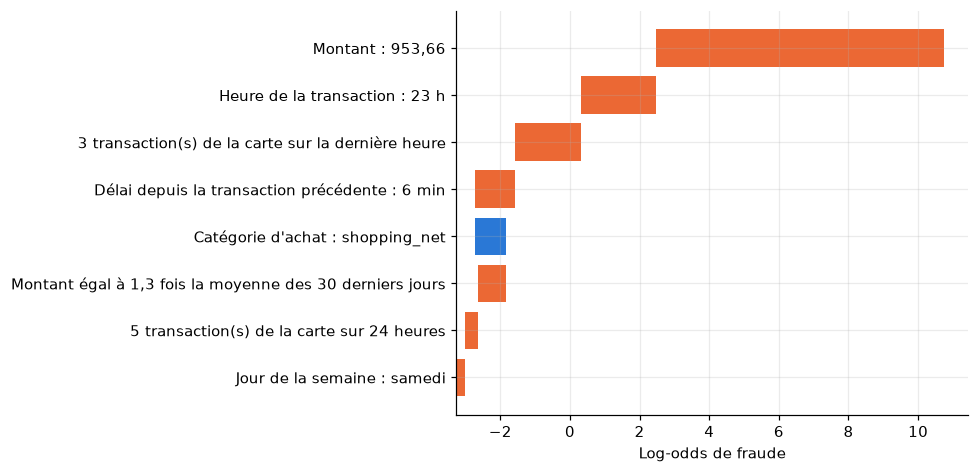

In [6]:
base = tableau.attrs["base"]
retenues = tableau.head(8)[::-1]
debuts = base + retenues["contribution"].cumsum() - retenues["contribution"]
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.barh(retenues["libelle"], retenues["contribution"], left=debuts, color=[ORANGE if v > 0 else BLEU for v in retenues["contribution"]])
ax.axvline(base, color="grey", linewidth=1)
ax.set_xlabel("Log-odds de fraude")
fig.tight_layout()
{"valeur_moyenne": base, "prediction": tableau.attrs["marge"], "probabilite_corrigee": tableau.attrs["probabilite_corrigee"]}

In [7]:
pd.DataFrame(explicabilite.codes_motifs(modele, ligne, 0, k=5))

,code,libelle,contribution
0,MONTANT,"Montant : 953,66",8.2506
1,HEURE,Heure de la transaction : 23 h,2.1696
2,VELOCITE_1H,3 transaction(s) de la carte sur la dernière h...,1.8925
3,DELAI_PRECEDENTE,Délai depuis la transaction précédente : 6 min,1.1326
4,RATIO_MOYENNE_30J,"Montant égal à 1,3 fois la moyenne des 30 dern...",0.7995


## Fausse alerte et fraude manquée

In [8]:
fausses = echantillon[alerte & ~fraude].sort_values("probabilite", ascending=False)
manquees = echantillon[~alerte & fraude].sort_values("probabilite", ascending=False)
for nom, jeu in (("Fausse alerte", fausses), ("Fraude manquée", manquees)):
    exemple = jeu.iloc[[0]].reset_index(drop=True)
    resultat_exemple = explicabilite.cascade(modele, exemple, 0)
    print(nom, "- probabilité", round(float(exemple.loc[0, "probabilite"]), 4))
    print(resultat_exemple.head(5)[["code", "libelle", "contribution"]].to_string(index=False))
    print()

Fausse alerte - probabilité 0.9927
            code                                            libelle  contribution
         MONTANT                                   Montant : 989,33        7.4943
           HEURE                     Heure de la transaction : 23 h        1.8141
       CATEGORIE                   Catégorie d'achat : shopping_pos       -1.0450
DELAI_PRECEDENTE     Délai depuis la transaction précédente : 4 min        0.9607
     VELOCITE_1H 2 transaction(s) de la carte sur la dernière heure        0.6556

Fraude manquée - probabilité 0.0231
             code                                        libelle  contribution
            HEURE                 Heure de la transaction : 22 h        1.6050
 DELAI_PRECEDENTE Délai depuis la transaction précédente : 2,0 h       -1.3014
          MONTANT                               Montant : 230,99        1.0144
        CATEGORIE                       Catégorie d'achat : home        0.6423
ECART_MONTANT_30J    Écart au montant hab

## Équité des alertes

In [9]:
groupes = pd.read_csv(RACINE / "resultats" / "equite_groupes.csv")
groupes[groupes["jeu"] == "test"].drop(columns="jeu")

,type,groupe,transactions,cartes,fraudes,taux_fraude,taux_alerte,rappel,precision,taux_fausses_alertes
8,genre,femmes,203357,467,686,0.0034,0.0092,0.9242,0.3396,0.0061
9,genre,hommes,167122,453,663,0.0040,0.0076,0.9789,0.5082,0.0038
10,age,25 à 34 ans,75596,184,237,0.0031,0.0083,0.9198,0.3460,0.0055
11,age,35 à 44 ans,80204,172,209,0.0026,0.0081,0.9426,0.3040,0.0056
12,age,45 à 54 ans,78011,196,289,0.0037,0.0083,0.9446,0.4226,0.0048
13,age,55 à 64 ans,45856,153,230,0.0050,0.0091,0.9826,0.5446,0.0041
14,age,65 ans et plus,60840,183,266,0.0044,0.0088,0.9511,0.4703,0.0047
15,age,moins de 25 ans,29972,62,118,0.0039,0.0089,0.9831,0.4345,0.0051


In [10]:
comparaison = pd.read_csv(RACINE / "resultats" / "equite_comparaison_modeles.csv")
comparaison

,modele,jeu,pr_auc,roc_auc,precision_a_k,rappel_a_k,seuil,vp,fn,fp,vn,alertes,accuracy,precision,rappel,f1,f2,mcc,cout
0,xgboost,validation,0.9171,0.9986,0.6283,0.9237,0.0272,1819,82,1944,366634,3763,0.9945,0.4834,0.9569,0.6423,0.8001,0.6781,"30,109.1100"
1,xgboost,test,0.8996,0.9983,0.4905,0.9377,0.0272,1283,66,1861,367269,3144,0.9948,0.4081,0.9511,0.5711,0.7512,0.6212,"28,907.5400"
2,xgboost_avec_age_genre,validation,0.9477,0.9990,0.6458,0.9495,0.0169,1843,58,1797,366781,3640,0.9950,0.5063,0.9695,0.6652,0.8195,0.6987,"24,703.1000"
3,xgboost_avec_age_genre,test,0.9357,0.9989,0.5029,0.9615,0.0169,1305,44,1743,367387,3048,0.9952,0.4281,0.9674,0.5936,0.7727,0.6419,"18,518.7400"


## Lecture

- Le montant domine l'explication, suivi de la catégorie et de l'heure : c'est une signature du simulateur, dont les montants de fraude suivent des lois propres à chaque catégorie.
- Âge et genre améliorent la performance mesurée mais ne sont pas retenus : l'âge d'une carte est quasi constant et identifie le porteur ; ce sont par ailleurs des caractéristiques protégées.
- Les taux d'alerte et de fausses alertes diffèrent entre hommes et femmes alors que le modèle n'utilise pas le genre : l'écart passe par des variables corrélées.